
---
# Curso: Data Mining - Semana 5
Docente: Soledad Espezúa (s.espezual@up.edu.pe)

---

<a name='manejoarchivos'></a>
# <font color=blue>Laboratorio Integración de tablas y unidad de análisis</font>

### Objetivo
Integrar varias fuentes sin perder la unidad de análisis y cerrar el flujo trabajado hasta ahora:

**comprender → diagnosticar calidad → integrar → validar → explorar → interpretar**.

# <font color=blue>Caso estudio: pacientes, atenciones y medicación</font>

Trabajaremos con cuatro tablas relacionadas:

- `Pacientes_Laboratorio.xlsx`
- `Atenciones.xlsx`
- `Medicamentos.xlsx`
- `Detalle_Medicacion.xlsx`

La misma información puede integrarse de formas distintas según la **pregunta** y la **unidad de análisis** que se desea conservar.

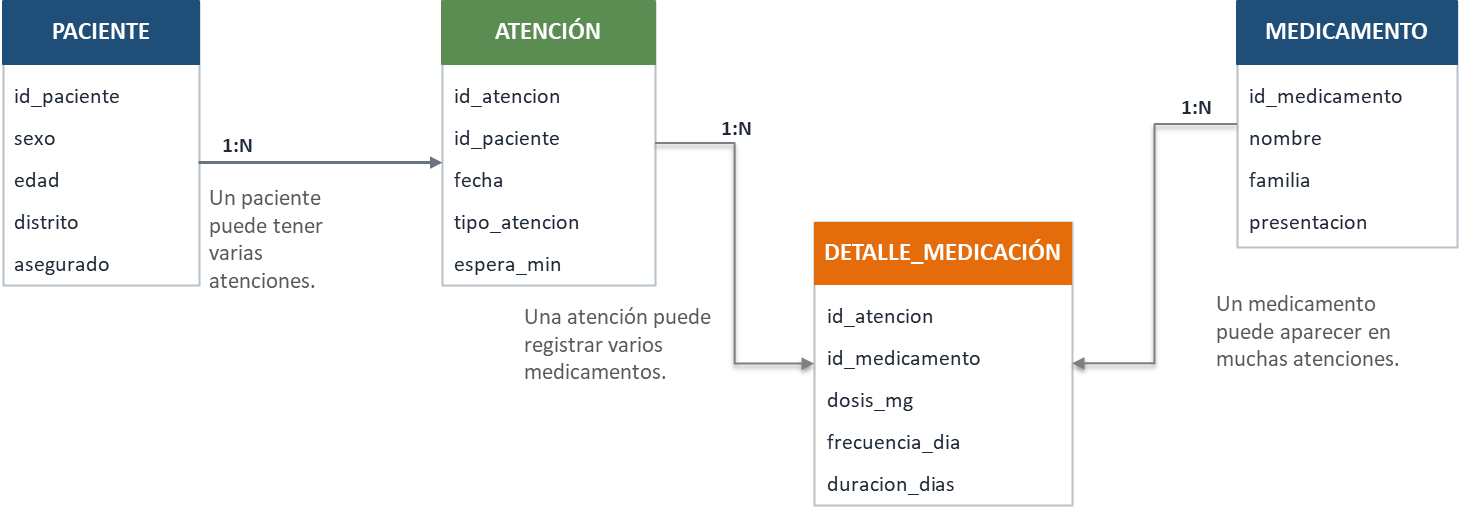

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pacientes = pd.read_excel("Pacientes.xlsx")
atenciones = pd.read_excel("Atenciones.xlsx")
medicamentos = pd.read_excel("Medicamentos.xlsx")
detalle = pd.read_excel("Detalle_Medicacion.xlsx")

print("Pacientes:", pacientes.shape)
print("Atenciones:", atenciones.shape)
print("Medicamentos:", medicamentos.shape)
print("Detalle de medicación:", detalle.shape)

# <font color=green>1. Comprender una fuente antes de integrar</font>

Para no repetir el mismo análisis cuatro veces, revise **solo la tabla `Pacientes`** y responda:

1. ¿Qué representa una fila?
2. ¿Cuál es su unidad de análisis o granularidad?
3. ¿Qué variable debería identificar de manera única a cada paciente?
4. ¿Qué tipos de variables reconoce?

Después aplicaremos la misma lógica al relacionarla con las demás tablas.

In [ ]:
display(pacientes.head(10))
pacientes.info()

### Respuesta de referencia

En `Pacientes`, una fila representa **un paciente**; por tanto, la unidad de análisis es **paciente**.  
La clave esperada es `id_paciente`.

Ejemplos:

- `edad`: numérica;
- `sexo`, `distrito`, `asegurado`: categóricas;
- `id_paciente`: identificador.

Antes de integrar otras tablas debemos preguntarnos siempre **qué representa una fila en cada fuente**.

# <font color=green>2. Diagnóstico básico de calidad</font>

Ejecute el siguiente diagnóstico sobre las cuatro tablas.

Observe:

- duplicados exactos;
- filas completamente vacías;
- columnas completamente vacías;
- columnas con valores faltantes.

> En esta sesión eliminaremos únicamente problemas estructurales evidentes.  
> Los valores faltantes que permanezcan **se detectan, pero todavía no se imputan**.

In [ ]:
tablas = {
    "Pacientes": pacientes,
    "Atenciones": atenciones,
    "Medicamentos": medicamentos,
    "Detalle_Medicacion": detalle
}

for nombre, df in tablas.items():
    print(f"\n--- {nombre} ---")

    # Excluimos las filas totalmente vacías antes de contar duplicados,
    # para no contarlas también como "duplicados exactos".
    no_vacias = df.loc[~df.isna().all(axis=1)]

    print("Duplicados exactos:", no_vacias.duplicated().sum())
    print("Filas completamente vacías:", df.isna().all(axis=1).sum())
    print("Columnas completamente vacías:",
          df.columns[df.isna().all(axis=0)].tolist())

    faltantes = df.isna().sum()
    print("Columnas con faltantes:")
    print(faltantes[faltantes > 0])

### ¿Qué podemos limpiar ahora?

Podemos eliminar directamente:

- duplicados exactos;
- filas completamente vacías;
- columnas completamente vacías.

En cambio, un faltante aislado en `distrito`, `espera_min`, `presentacion` o `dosis_mg` requiere analizar **por qué falta** y qué efecto tendría eliminarlo o imputarlo. Su tratamiento se verá posteriormente.

In [ ]:
def limpieza_inicial(df):
    # Elimina duplicados exactos.
    df = df.drop_duplicates()

    # Elimina únicamente filas donde TODAS las columnas están vacías.
    df = df.dropna(how="all")

    # Elimina únicamente columnas completamente vacías.
    df = df.dropna(axis=1, how="all")

    return df.copy()

pacientes = limpieza_inicial(pacientes)
atenciones = limpieza_inicial(atenciones)
medicamentos = limpieza_inicial(medicamentos)
detalle = limpieza_inicial(detalle)

print("Dimensiones después de la limpieza inicial:")
print("Pacientes:", pacientes.shape)
print("Atenciones:", atenciones.shape)
print("Medicamentos:", medicamentos.shape)
print("Detalle:", detalle.shape)

# <font color=green>3. Relaciones y claves antes del `merge()`</font>

Relaciones del caso:

**Paciente 1 → N Atenciones**  
**Atención 1 → N Detalles de medicación**  
**Medicamento 1 → N Detalles de medicación**

Antes de integrar, verifique que las claves de las tablas padre sean únicas.

In [ ]:
print("¿id_paciente es único en Pacientes?:",
      pacientes["id_paciente"].is_unique)

print("¿id_atencion es único en Atenciones?:",
      atenciones["id_atencion"].is_unique)

print("¿id_medicamento es único en Medicamentos?:",
      medicamentos["id_medicamento"].is_unique)

print("\nAtenciones por paciente:")
display(atenciones["id_paciente"].value_counts().sort_index())

# <font color=red>CASO A — Unidad de análisis: PACIENTE</font>

> **Quiero estudiar características de los pacientes** y complementar su información con un resumen de sus atenciones y medicamentos.

La base final debe conservar:

**una fila = un paciente**.

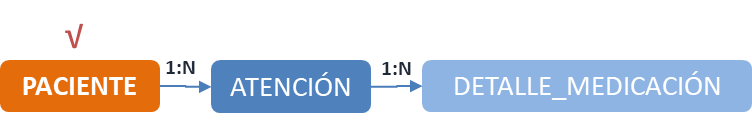

## <font color=d00000>4. ¿Qué ocurre si integramos Pacientes y Atenciones directamente?</font>

Un `merge()` puede ejecutarse correctamente y, aun así, producir una base con una granularidad distinta de la que necesitamos.

In [ ]:
paciente_atencion_directo = pacientes.merge(
    atenciones,
    on="id_paciente",
    how="left"
)

print("Filas en Pacientes:", len(pacientes))
print("Filas después del merge directo:", len(paciente_atencion_directo))
print("¿id_paciente sigue siendo único?:",
      paciente_atencion_directo["id_paciente"].is_unique)

In [ ]:
paciente_atencion_directo.head()

**Interpretación:** no se conserva una fila por paciente.  
Los pacientes con varias atenciones aparecen repetidos una vez por cada atención.

Si queremos conservar la unidad **paciente**, debemos <font color=blue> llevar primero la tabla hija `Atenciones` a esa misma granularidad.</font>

In [ ]:
atenciones.head()

## <font color=d00000>5. `groupby()` para cambiar la granularidad</font>

`groupby()` permite reunir las filas que pertenecen a una misma unidad y resumirlas.

Estructura general:

`df.groupby("clave").agg(nueva_variable=("variable_original", "operación"))`

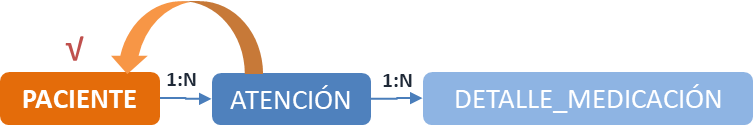

Para conservar una fila por paciente, primero debemos resumir las atenciones de cada paciente.

`groupby("id_paciente")` agrupa las filas que pertenecen al mismo paciente y `agg()` permite calcular diferentes resúmenes para cada grupo:

* número de atenciones;
* primera y última fecha de atención;
* tiempo promedio de espera.

`reset_index()` vuelve a dejar id_paciente como una columna de la tabla.

In [ ]:
resumen_atenciones_por_paciente = (
    atenciones.groupby("id_paciente").agg(
        n_atenciones=("id_atencion", "nunique"), # cuenta atenciones distintas por paciente
        fecha_primera_atencion=("fecha", "min"),
        fecha_ultima_atencion=("fecha", "max"),
        espera_promedio=("espera_min", "mean")
    )
    .reset_index()
)

display(resumen_atenciones_por_paciente)

También podemos resumir las prescripciones (Detalle_medicación) a nivel paciente.  
Primero llevamos `id_paciente` al detalle de medicación y después agrupamos.

In [ ]:
detalle.head()

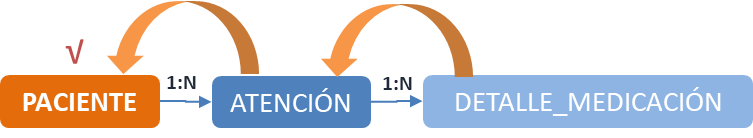

En un **left merge,** se coloca a la izquierda la tabla cuya unidad de análisis desea conservar.

In [ ]:
# Añadimos el id_paciente a cada registro de medicación
detalle_paciente = detalle.merge(
    atenciones[["id_atencion", "id_paciente"]],  # clave de unión (id_atencion) + variable que queremos agregar(id_paciente)
    on="id_atencion",  # clave común entre ambas tablas
    how="left",
    validate="many_to_one"  # varios registros de detalle pueden pertenecer a una misma atención
)

In [ ]:
detalle_paciente.head()

In [ ]:
# Resumimos las prescripciones para obtener una fila por paciente
resumen_medicacion_paciente = (
    detalle_paciente.groupby("id_paciente").agg(
        n_prescripciones=("id_medicamento", "size"),          # total de prescripciones
        n_medicamentos_distintos=("id_medicamento", "nunique") # medicamentos diferentes
    )
    .reset_index()
)

display(resumen_medicacion_paciente)

Ahora integramos los dos resúmenes con la tabla `Pacientes`. Como ambos resúmenes ya fueron llevados a nivel paciente, la relación esperada es 1:1 y `id_paciente` debe mantenerse único en la base final.

In [ ]:
# Construimos la base final a nivel paciente
base_paciente = (
    pacientes.merge(
        resumen_atenciones_por_paciente, # Agregamos el resumen de atenciones de cada paciente
        on="id_paciente",
        how="left",
        validate="one_to_one"
    )
    .merge(
        resumen_medicacion_paciente, # Agregamos el resumen de medicamentos de cada paciente
        on="id_paciente",
        how="left",
        validate="one_to_one"
    )
)

# Verificamos que la base conserve una fila por paciente
print("Base paciente:", base_paciente.shape)
print("¿id_paciente es único?:",base_paciente["id_paciente"].is_unique)

display(base_paciente.head())

# <font color=red>CASO B — Unidad de análisis: ATENCIÓN</font>

> **Quiero analizar los tipos de atención**, sus tiempos de espera y características de los pacientes.

Ahora la base debe conservar:

**una fila = una atención**.

`Pacientes` puede integrarse directamente porque cada atención pertenece a un solo paciente.  
`Detalle_Medicacion`, en cambio, debe resumirse primero porque una atención puede tener varios medicamentos.

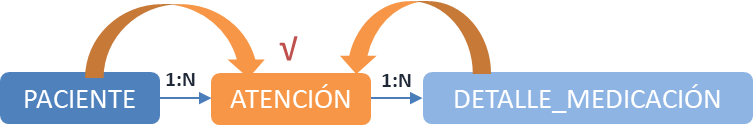

Como la unidad de análisis es atención, partimos de la tabla `Atenciones`. Las características del paciente pueden incorporarse directamente porque cada atención pertenece a un solo paciente. En cambio, `Detalle_Medicacion` debe resumirse previamente por `id_atencion`, ya que una atención puede tener varias prescripciones.

In [ ]:
# Construimos una base cuya unidad de análisis sea la atención.
# Primero añadimos a cada atención las características del paciente.
base_atencion = atenciones.merge(
    pacientes,
    on="id_paciente",
    how="left",
    validate="many_to_one"   # muchas atenciones pueden pertenecer a un mismo paciente
)

# Como una atención puede tener varios medicamentos,
# resumimos primero el detalle de medicación a nivel de atención.
resumen_medicacion_atencion = (
    detalle.groupby("id_atencion").agg(
        n_prescripciones=("id_medicamento", "size"),          # total de prescripciones
        n_medicamentos_distintos=("id_medicamento", "nunique") # medicamentos diferentes
    )
    .reset_index()
)

# Añadimos el resumen de medicación a cada atención.
base_atencion = base_atencion.merge(
    resumen_medicacion_atencion,
    on="id_atencion",
    how="left",
    validate="one_to_one"    # ambas tablas tienen una sola fila por atención
)

# Verificamos que la base final conserve una fila por atención.
print("Base atención:", base_atencion.shape)
print("¿id_atencion es único?:", base_atencion["id_atencion"].is_unique)

display(base_atencion.head())

# <font color=red>CASO C — Unidad de análisis: MEDICAMENTO PRESCRITO</font>

> **Quiero analizar los medicamentos prescritos, dosis y combinaciones.**

La tabla principal es `Detalle_Medicacion`.

Una fila representa **un medicamento específico prescrito en una atención específica**.

La clave esperada es compuesta:

`id_atencion + id_medicamento`.

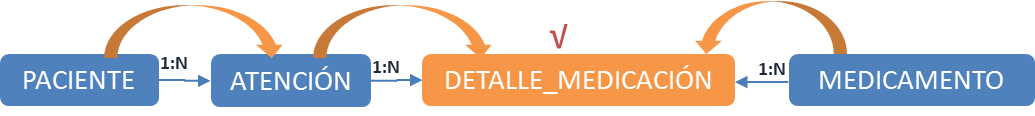

Como la unidad de análisis es medicamento prescrito en una atención, partimos de `Detalle_Medicacion` y conservamos cada una de sus filas. No necesitamos hacer groupby(), porque las demás tablas aportan información de entidades padre: cada registro del detalle corresponde a un solo medicamento, una sola atención y un solo paciente.

In [ ]:
# Construimos una base cuya unidad de análisis sea
# un medicamento prescrito en una atención.
base_medicacion = (
    detalle.merge(
        medicamentos, # Añadimos las características del medicamento.
        on="id_medicamento",
        how="left",
        validate="many_to_one"   # muchos registros pueden referirse al mismo medicamento
    )
    .merge(
        atenciones,  # Añadimos la información de la atención.
        on="id_atencion",
        how="left",
        validate="many_to_one"   # varios medicamentos pueden pertenecer a una misma atención
    )
    .merge(
        pacientes, # Añadimos las características del paciente.
        on="id_paciente",
        how="left",
        validate="many_to_one"   # varias prescripciones pueden pertenecer al mismo paciente
    )
)

# Verificamos el tamaño de la base final.
print("Base medicación:", base_medicacion.shape)

# La clave de esta unidad de análisis es compuesta:
# id_atencion + id_medicamento.
duplicados_clave = base_medicacion.duplicated(subset=["id_atencion", "id_medicamento"]).sum()

print("Duplicados de la clave compuesta:",duplicados_clave)

display(base_medicacion.head())

#<font color=green>6. Comparación de las tres bases</font>
* Caso A, paciente: hay que agregar tablas hijas.
* Caso B, atención: hay que agregar el detalle de medicación.
* Caso C, medicamento prescrito: no agregamos, porque precisamente queremos conservar ese nivel de detalle.



| Base | Unidad de análisis | Clave |
|---|---|---|
| `base_paciente` | un paciente | `id_paciente` |
| `base_atencion` | una atención | `id_atencion` |
| `base_medicacion` | un medicamento prescrito en una atención | `id_atencion + id_medicamento` |

**Regla:** antes de integrar, defina cuál será la unidad de análisis de la base final.



---



# <font color=blue>EDA — De la base integrada al hallazgo</font>

Una vez que la base conserva la unidad correcta, podemos explorarla.

* Distribución de una variable numérica → `histplot()`
* Comparación de una numérica entre grupos → `boxplot()`
* Relación entre dos numéricas → `scatterplot()`
* Frecuencia de categorías → `countplot()`

No repetiremos todos los gráficos vistos anteriormente. Revisaremos dos ejemplos y luego cada grupo formulará su propio EDA.

## <font color=green>7. Comparación entre grupos</font>  

**Pregunta:** ¿el tiempo de espera cambia según el tipo de atención?


Unidad de análisis: **atención**.  
Variables: `espera_min` (numérica) y `tipo_atencion` (categórica).  
Gráfico: **boxplot**.

In [ ]:
base_atencion.head()

¿Cuál debemos usar: media o mediana, para comparar los tipos de atención?

In [ ]:
resumen_espera = (
    base_atencion
    .groupby("tipo_atencion")["espera_min"]
    .agg(["mean", "median"])
    .round(1)
)

display(resumen_espera)

* Para el **boxplot** la mediana representa la medida central de cada grupo, no la media.

* Además, para *tiempos de espera* la mediana suele ser especialmente útil porque es menos sensible a valores extremos.

In [ ]:
print("Mediana de espera por tipo de atención:")
base_atencion.groupby("tipo_atencion")["espera_min"].median().sort_values()

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(
    data=base_atencion,
    x="tipo_atencion",
    y="espera_min"
)
plt.title("Tiempo de espera según tipo de atención")
plt.xlabel("Tipo de atención")
plt.ylabel("Tiempo de espera (min)")
plt.show()



---


### Lectura del gráfico

Una conclusión debe separar:

**observación → evidencia → interpretación → límite**

Ejemplo:

- **Observación:** los tiempos de espera presentan diferencias entre los tipos de atención.
- **Evidencia:** las medianas y la posición de las cajas cambian entre grupos.
- **Interpretación:** en esta muestra, algunos tipos de atención tienden a registrar mayores tiempos de espera.
- **Límite:** el gráfico no demuestra que el tipo de atención sea la causa de esas diferencias.



---



**Hallazgo esperado**

En este conjunto de datos, el Tipo de atención **Control** presenta los tiempos de espera más altos: su mediana es aproximadamente 34.5 min, frente a 24.5 min en **Consulta** y 12 min en **Emergencia**.

Las cajas y medianas se encuentran desplazadas hacia valores mayores para Control.

Sin embargo, no podemos afirmar que el tipo de atención cause un determinado tiempo de espera. Además, el número de observaciones es reducido.

## <font color=green>8. Frecuencia de categorías</font>  
**Pregunta:** ¿qué medicamentos aparecen con mayor frecuencia en las prescripciones?

Unidad de análisis: **medicamento prescrito**.  
Variable: `nombre` (categórica).  
Gráfico: **countplot**.

In [ ]:
orden = base_medicacion["nombre"].value_counts().index

plt.figure(figsize=(6, 3))
ax = sns.countplot(
    data=base_medicacion,
    y="nombre",
    order=orden,
    hue="nombre",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=2)

plt.title("Medicamentos registrados con mayor frecuencia")
plt.xlabel("Número de prescripciones")
plt.ylabel("Medicamento")
plt.show()

**Hallazgo esperado**

**Paracetamol** es el medicamento que aparece con mayor frecuencia, con 7 prescripciones, seguido por Omeprazol y Losartán, con 5 cada uno.

El gráfico permite describir frecuencia de aparición, pero no permite afirmar cuál medicamento es más efectivo ni cuál debería prescribirse con mayor frecuencia.

# <font color=green>9. Distribución — ¿Cómo se comporta el tiempo de espera?</font>

Trabaje con `base_atencion`.

**Pregunta:** ¿Cómo se distribuye el tiempo de espera de las atenciones?

Antes de graficar, verifique cuántos registros tienen un valor válido de `espera_min`.

> El valor faltante de `espera_min` se mantiene. En esta sesión no se imputa.

In [ ]:
print("Atenciones totales:", len(base_atencion))
print("Atenciones con espera registrada:", base_atencion["espera_min"].notna().sum())

plt.figure(figsize=(4,2))

sns.histplot(
    data=base_atencion,
    x="espera_min",
    bins=7,
    kde=True
)

plt.title("Distribución del tiempo de espera")
plt.xlabel("Tiempo de espera (min)")
plt.ylabel("Número de atenciones")
plt.show()

# <font color=green>10. Relación — ¿La edad está asociada con el tiempo de espera?</font>

Analice la relación entre `edad` y `espera_min` en `base_atencion`.

Use `asegurado` para diferenciar visualmente los grupos si considera que aporta información.

Presente:

**Variables involucradas y tipo:**  
**Gráfico elegido:**  
**Hallazgo sustentado:**  
**¿Qué NO puede concluirse?:**

In [ ]:
plt.figure(figsize=(6,3))

sns.scatterplot(
    data=base_atencion,
    x="edad",
    y="espera_min",
    hue="asegurado",
    s=80
)

plt.title("Edad y tiempo de espera")
plt.xlabel("Edad (años)")
plt.ylabel("Tiempo de espera (min)")
plt.show()

corr = base_atencion["edad"].corr(base_atencion["espera_min"])
print("Correlación edad-espera:", round(corr, 2))

**Hallazgo esperado**

Se observa una **asociación positiva** entre `edad` y `tiempo de espera`; la **correlación** es aproximadamente **0.68**. Los puntos sugieren que las edades mayores aparecen con frecuencia asociadas a tiempos de espera mayores.

Sin embargo, el gráfico no demuestra causalidad. La asociación podría estar influida por otras variables, por ejemplo el **tipo de atención**. El color permite explorar si la **persona es asegurada**, pero la muestra es demasiado pequeña para sostener conclusiones fuertes sobre diferencias entre asegurados y no asegurados.

# <font color=blue>Tarea grupal — Aplicación al proyecto</font>

Trabaje ahora con los datos de su proyecto.

1. Indique claramente su **unidad de análisis**.
2. Identifique la **tabla principal** y su clave.
3. Si usa varias tablas, indique la relación entre ellas (`1:1`, `1:N` o `N:M`).
4. Identifique si alguna tabla debe **agregarse antes de integrarla** para conservar la unidad de análisis.
5. Realice un diagnóstico básico de calidad y documente los problemas encontrados.
6. Construya o actualice su base integrada y verifique que la clave esperada conserve su unicidad.
7. Formule **una pregunta de EDA**, seleccione el gráfico apropiado y escriba:
   - observación;
   - evidencia;
   - interpretación;
   - límite.

> El objetivo no es hacer más gráficos, sino construir una base coherente con la pregunta y obtener un hallazgo sustentado.